# ADS 505 Technical Notebook: Predicting U.S. Flight Departure Delays

Team: 4 (individual project, instructor-approved)  
Author: Michael Rosalia  
GitHub repository: https://github.com/mrosalia96/ads505-flight-delay-prediction

Predict pre-departure delay risk (≥ 15 minutes) for flights originating at SAN, LAX, PHX, DEN, and SEA in 2023, using BTS on-time performance and NOAA ASOS weather. The intended use is a same-day watch list refreshed before each busy departure window, using the latest airport weather available at decision time, so leaders can focus staffing, turns, and passenger updates on the highest-risk flights.


In [1]:
# All package imports live in this first code cell.
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
 average_precision_score,
 classification_report,
 confusion_matrix,
 precision_recall_fscore_support,
 roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid", context="notebook")

RANDOM_STATE = 42
PROJECT_ROOT = Path("..").resolve()
RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
BTS_DIR = RAW_DIR / "bts"
NOAA_DIR = RAW_DIR / "noaa"

ORIGIN_AIRPORTS = ("SAN", "LAX", "PHX", "DEN", "SEA")
ANALYSIS_YEAR = 2023

sys.path.insert(0, str(PROJECT_ROOT / "src"))
from build_flights_sample import build_sample, default_sample_path # noqa: E402

print("Project root:", PROJECT_ROOT)


Project root: /Users/mike/Desktop/ADS505/Final Project/ads505-flight-delay-prediction


## 1. Problem statement and data description

Problem. Airlines and airports often learn about departure delays as they unfold. This project builds a delay-risk score for scheduled departures so operations leaders can prioritize staffing, buffers, and passenger communication before pushback. The decision is framed as a same-day watch list before each busy departure window (hours ahead), not an 8 a.m. plan that must already know evening weather with perfect accuracy.

Data. U.S. DOT BTS Reporting Carrier On-Time Performance for calendar year 2023, filtered to origin airports SAN, LAX, PHX, DEN, and SEA. NOAA weather is joined in Section 3.5. Acquisition details and APA citations: `docs/data_sources.md`.

How data are obtained (reproducibility). This is not a live filtered API pull. Peers download the same public monthly ZIP files from fixed TranStats URLs (`src/download_bts.py`), then run `src/build_flights_sample.py` to keep only our five origins. Raw ZIPs and the processed parquet stay on disk (gitignored); the repo stores the scripts and docs so anyone can rebuild the sample and re-run this notebook.

Target. Prefer BTS `DepDel15` (1 = departure delay ≥ 15 minutes). Rows with missing delay outcome or cancelled flights are handled explicitly below.


In [2]:
# Prefer an existing processed sample; rebuild only if missing.
# To force a rebuild: build_sample(year=ANALYSIS_YEAR, origins=ORIGIN_AIRPORTS)
# Requires raw ZIPs from: python src/download_bts.py --year 2023
sample_path = default_sample_path(ANALYSIS_YEAR)
if sample_path is None:
 sample_path = build_sample(year=ANALYSIS_YEAR, origins=ORIGIN_AIRPORTS)
print("Sample file:", sample_path)


Sample file: /Users/mike/Desktop/ADS505/Final Project/ads505-flight-delay-prediction/data/processed/flights_origins_2023.parquet


In [3]:
# Load the processed sample and report basic shape / delay rate.
flights = pd.read_parquet(sample_path) if sample_path.suffix == ".parquet" else pd.read_csv(
 sample_path, parse_dates=["FlightDate"]
)

# Modelling set: exclude cancelled flights; require a defined 15-min delay flag.
mask_usable = (flights["Cancelled"] == 0) & flights["DepDel15"].notna()
flights_model = flights.loc[mask_usable].copy()
flights_model["DepDel15"] = flights_model["DepDel15"].astype(int)

print(f"Raw filtered rows: {len(flights):,}")
print(f"Usable (not cancelled, DepDel15 known): {len(flights_model):,}")
print(f"Date range: {flights_model['FlightDate'].min().date()} → {flights_model['FlightDate'].max().date()}")
print("Rows by origin:")
print(flights_model["Origin"].value_counts().reindex(list(ORIGIN_AIRPORTS)))
print(f"Overall DepDel15 rate: {flights_model['DepDel15'].mean():.3%}")


Raw filtered rows: 914,796
Usable (not cancelled, DepDel15 known): 906,160
Date range: 2023-01-01 → 2023-12-31
Rows by origin:
Origin
SAN     90048
LAX    192780
PHX    175547
DEN    284959
SEA    162826
Name: count, dtype: int64
Overall DepDel15 rate: 21.633%


## 2. Exploratory data analysis (EDA)

Charts appear only where discussed. Focus: where delay risk concentrates by airport, month, scheduled hour, day of week, and carrier - patterns an operations lead would recognize without weather yet.


### 2.1 Delay rate by origin airport

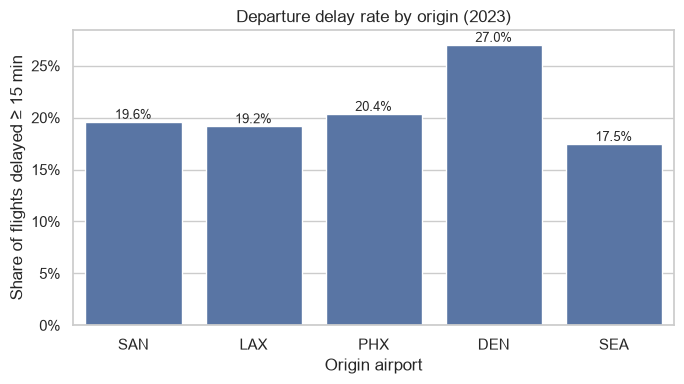

In [4]:
delay_by_origin = (
 flights_model.groupby("Origin", as_index=False)["DepDel15"]
 .mean()
 .rename(columns={"DepDel15": "delay_rate"})
)
delay_by_origin["Origin"] = pd.Categorical(
 delay_by_origin["Origin"], categories=list(ORIGIN_AIRPORTS), ordered=True
)
delay_by_origin = delay_by_origin.sort_values("Origin")

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=delay_by_origin, x="Origin", y="delay_rate", color="#4C72B0", ax=ax)
ax.set_ylabel("Share of flights delayed ≥ 15 min")
ax.set_xlabel("Origin airport")
ax.set_title("Departure delay rate by origin (2023)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
for bar, rate in zip(ax.patches, delay_by_origin["delay_rate"]):
 ax.annotate(f"{rate:.1%}", (bar.get_x() + bar.get_width() / 2, bar.get_height()),
 ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()


DEN has the highest 15+ minute departure-delay rate (~27%), while SEA is lowest (~17%). SAN sits near the middle (~20%). A single national average would hide that hub-level risk differs by roughly 10 percentage points across this sample.

### 2.2 Seasonality by month

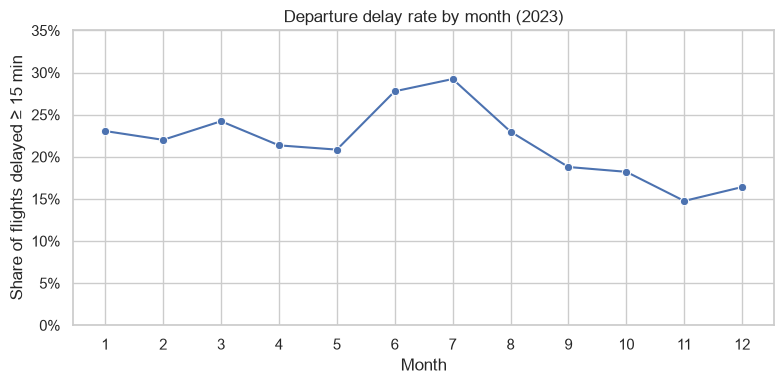

In [5]:
delay_by_month = (
 flights_model.groupby("Month", as_index=False)["DepDel15"]
 .mean()
 .rename(columns={"DepDel15": "delay_rate"})
)

fig, ax = plt.subplots(figsize=(8, 4))
sns.lineplot(data=delay_by_month, x="Month", y="delay_rate", marker="o", ax=ax)
ax.set_xticks(range(1, 13))
ax.set_ylabel("Share of flights delayed ≥ 15 min")
ax.set_xlabel("Month")
ax.set_title("Departure delay rate by month (2023)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.set_ylim(0, max(0.35, delay_by_month["delay_rate"].max() * 1.15))
plt.tight_layout()
plt.show()


Delay risk peaks in June-July (~28-29%) and is lowest in November (~15%). Summer operational pressure shows up clearly in this five-airport sample; a model that ignores month will miss a large, predictable swing.


### 2.3 Time-of-day pattern

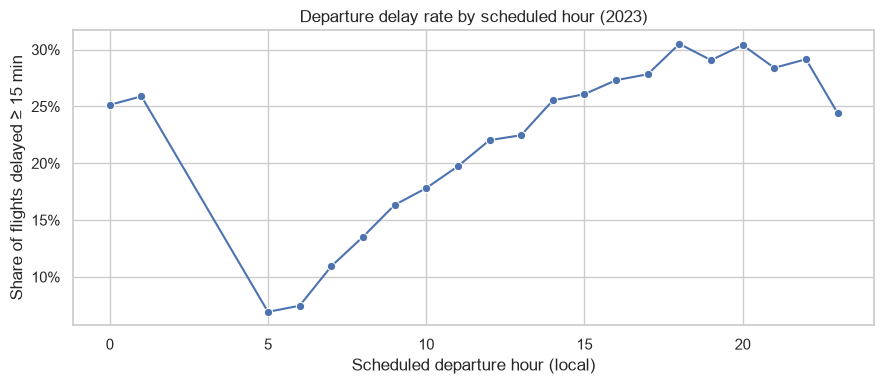

In [6]:
flights_model = flights_model.copy()
flights_model["crs_dep_hour"] = (flights_model["CRSDepTime"] // 100).astype("Int64")

delay_by_hour = (
 flights_model.dropna(subset=["crs_dep_hour"])
 .groupby("crs_dep_hour", as_index=False)
 .agg(delay_rate=("DepDel15", "mean"), n_flights=("DepDel15", "size"))
)
# Keep hours with enough volume for a stable rate
delay_by_hour = delay_by_hour[delay_by_hour["n_flights"] >= 500]

fig, ax = plt.subplots(figsize=(9, 4))
sns.lineplot(data=delay_by_hour, x="crs_dep_hour", y="delay_rate", marker="o", ax=ax)
ax.set_ylabel("Share of flights delayed ≥ 15 min")
ax.set_xlabel("Scheduled departure hour (local)")
ax.set_title("Departure delay rate by scheduled hour (2023)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
plt.tight_layout()
plt.show()


Early departure windows are comparatively reliable (roughly 7-11% delayed at 05:00-07:00 scheduled), while late afternoon and evening windows reach about 28-31%. That asymmetry matters for staffing: the same airport needs different attention at 6 a.m. vs 6 p.m.


### 2.4 Day of week

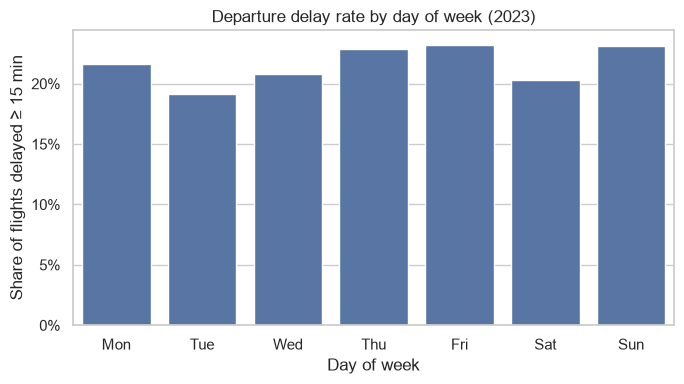

In [7]:
dow_labels = {
 1: "Mon",
 2: "Tue",
 3: "Wed",
 4: "Thu",
 5: "Fri",
 6: "Sat",
 7: "Sun",
}

delay_by_dow = (
 flights_model.groupby("DayOfWeek", as_index=False)["DepDel15"]
 .mean()
 .rename(columns={"DepDel15": "delay_rate"})
)
delay_by_dow["day"] = delay_by_dow["DayOfWeek"].map(dow_labels)

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=delay_by_dow, x="day", y="delay_rate", color="#4C72B0", ax=ax,
 order=[dow_labels[i] for i in range(1, 8)])
ax.set_ylabel("Share of flights delayed ≥ 15 min")
ax.set_xlabel("Day of week")
ax.set_title("Departure delay rate by day of week (2023)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
plt.tight_layout()
plt.show()


Thursday, Friday, and Sunday sit at the high end (~23%), while Tuesday is lowest (~19%). The day-of-week swing is real but smaller than the airport and time-of-day gaps, so it is a useful secondary feature rather than the main driver.

### 2.5 Reporting airline (high-volume carriers)

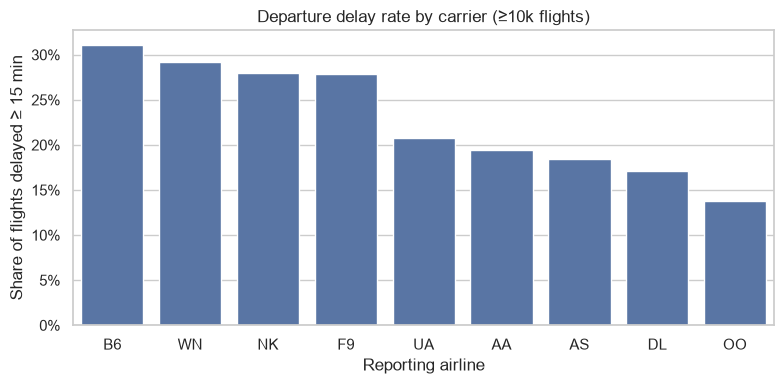

In [8]:
carrier_stats = (
 flights_model.groupby("Reporting_Airline", as_index=False)
 .agg(delay_rate=("DepDel15", "mean"), n_flights=("DepDel15", "size"))
)
# Stable rates only: carriers with at least 10,000 departures in the sample
carrier_stats = carrier_stats[carrier_stats["n_flights"] >= 10_000].sort_values(
 "delay_rate", ascending=False
)

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=carrier_stats, x="Reporting_Airline", y="delay_rate", color="#4C72B0", ax=ax)
ax.set_ylabel("Share of flights delayed ≥ 15 min")
ax.set_xlabel("Reporting airline")
ax.set_title("Departure delay rate by carrier (≥10k flights)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
plt.tight_layout()
plt.show()


Among high-volume carriers, delay rates still differ a lot: Southwest (WN) is near ~29%, while SkyWest (OO) is near ~14%. Carrier identity is informative for prioritizing attention, but it can also proxy route mix and airport exposure, so we will treat it as a feature and check that it does not simply recreate the origin effect later.


### 2.6 EDA implications for modeling

Origin, scheduled hour, and month patterns are visible in the raw rates; day of week and reporting airline add secondary structure. Because the later modeling split trains only on January-August, month-number effects cannot transfer cleanly into Sep-Dec, so weather and hour remain especially important. Next: preprocess these fields, join origin weather, then split by time.


## 3. Data pre-processing

Goal: freeze a clean modeling table with pre-departure features only (no delay-cause fields), document missingness and outliers, and check pairwise correlation among numeric candidates. Weather columns will be added in a later step before the train/validation/test split.


### 3.1 Missing values and basic cleaning

In [9]:
# Ensure hour feature exists if earlier cells were run out of order
if "crs_dep_hour" not in flights_model.columns:
 flights_model = flights_model.copy()
 flights_model["crs_dep_hour"] = (flights_model["CRSDepTime"] // 100).astype("Int64")

feature_candidates = [
 "Month",
 "DayOfWeek",
 "crs_dep_hour",
 "Origin",
 "Dest",
 "Reporting_Airline",
 "Distance",
 "CRSElapsedTime",
]
target_col = "DepDel15"

missing_report = (
 flights_model[feature_candidates + [target_col]]
 .isna()
 .mean()
 .sort_values(ascending=False)
 .rename("pct_missing")
)
print("Missingness among candidate fields:")
print(missing_report.map(lambda x: f"{x:.3%}"))

# Drop rows missing any candidate feature or the target (rare after cancel filter)
before = len(flights_model)
flights_clean = flights_model.dropna(subset=feature_candidates + [target_col]).copy()
after = len(flights_clean)
print(f"\nRows before dropna: {before:,}")
print(f"Rows after dropna: {after:,} (removed {before - after:,})")


Missingness among candidate fields:
Month                0.000%
DayOfWeek            0.000%
crs_dep_hour         0.000%
Origin               0.000%
Dest                 0.000%
Reporting_Airline    0.000%
Distance             0.000%
CRSElapsedTime       0.000%
DepDel15             0.000%
Name: pct_missing, dtype: str

Rows before dropna: 906,160
Rows after dropna: 906,160 (removed 0)


Cancelled flights and rows without `DepDel15` were already removed. No candidate features were missing in this filtered sample, so no additional rows were dropped for missing predictors. The dropna step remains as a safety check so train/validation/test share a consistent schema.


### 3.2 Outliers on distance and elapsed time

                   count         mean        std   min     1%     5%     95%  \
Distance        906160.0  1068.729549  688.93508  73.0  109.0  236.0  2475.0   
CRSElapsedTime  906160.0   166.394576  79.319963  40.0   53.0   70.0   328.0   
crs_dep_hour    906160.0    13.328645   5.091881   0.0    5.0    6.0    22.0   

                   99%     max  
Distance        2677.0  3414.0  
CRSElapsedTime   375.0   479.0  
crs_dep_hour      23.0    23.0  

Distance outside 1st-99th percentile: 14,094 (1.56%) - kept for now; tree models handle heavy tails well.


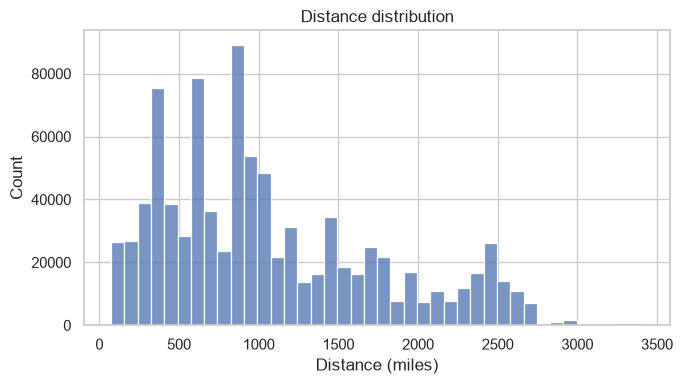

In [10]:
numeric_check = ["Distance", "CRSElapsedTime", "crs_dep_hour"]
summary = flights_clean[numeric_check].describe(percentiles=[0.01, 0.05, 0.95, 0.99]).T
print(summary)

q01 = flights_clean["Distance"].quantile(0.01)
q99 = flights_clean["Distance"].quantile(0.99)
extreme_dist = (flights_clean["Distance"] < q01) | (flights_clean["Distance"] > q99)
print(
    f"\nDistance outside 1st-99th percentile: {extreme_dist.sum():,} "
    f"({extreme_dist.mean():.2%}) - kept for now; tree models handle heavy tails well."
)

fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(flights_clean["Distance"], bins=40, ax=ax, color="#4C72B0")
ax.set_title("Distance distribution")
ax.set_xlabel("Distance (miles)")
plt.tight_layout()
plt.show()


Distance and scheduled block time are right-skewed (short-haul heavy with a long-haul tail), which is expected for these hubs. We keep extreme distance rows rather than winsorizing: they are real markets, and tree-based models can split on them. Linear models can use a log-distance transform later if needed.


### 3.3 Correlated numeric features

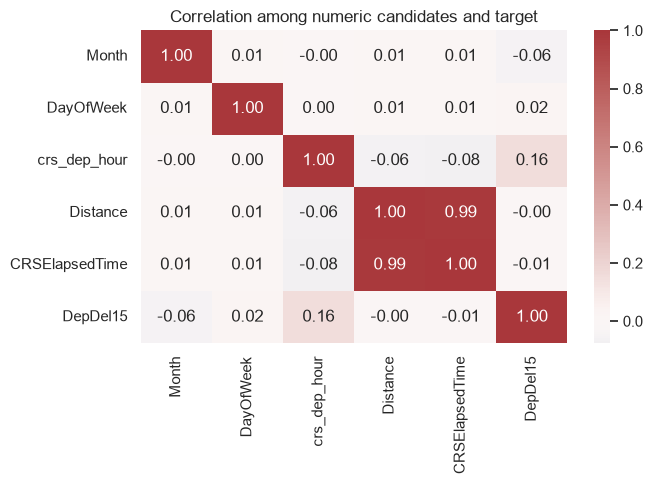

Distance vs CRSElapsedTime correlation: 0.991


In [11]:
corr_cols = ["Month", "DayOfWeek", "crs_dep_hour", "Distance", "CRSElapsedTime", target_col]
corr = flights_clean[corr_cols].corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax)
ax.set_title("Correlation among numeric candidates and target")
plt.tight_layout()
plt.show()

print(
 "Distance vs CRSElapsedTime correlation:",
 f"{corr.loc['Distance', 'CRSElapsedTime']:.3f}",
)


`Distance` and `CRSElapsedTime` are highly correlated (same underlying trip length). For the baseline feature set we keep Distance and drop scheduled elapsed time to reduce redundancy. Month, day-of-week, and hour are weakly related to the target individually - useful in combination with airport/carrier and weather.


### 3.4 Feature list freeze (pre-weather)

In [12]:
MODEL_FEATURES = [
 "Month",
 "DayOfWeek",
 "crs_dep_hour",
 "Origin",
 "Dest",
 "Reporting_Airline",
 "Distance",
]
LEAKAGE_EXCLUDED = [
 "DepDelay",
 "DepDelayMinutes",
 "DepTime",
 "CarrierDelay",
 "WeatherDelay",
 # and other post-departure / delay-cause fields not retained in the sample
]

flights_model_ready = flights_clean[MODEL_FEATURES + [target_col, "FlightDate"]].copy()
flights_model_ready[target_col] = flights_model_ready[target_col].astype(int)

print("Frozen features:", MODEL_FEATURES)
print("Explicitly excluded as leakage / post-outcome:", LEAKAGE_EXCLUDED)
print(f"Modeling table shape: {flights_model_ready.shape}")
print(f"Positive class rate: {flights_model_ready[target_col].mean():.3%}")
flights_model_ready.head()


Frozen features: ['Month', 'DayOfWeek', 'crs_dep_hour', 'Origin', 'Dest', 'Reporting_Airline', 'Distance']
Explicitly excluded as leakage / post-outcome: ['DepDelay', 'DepDelayMinutes', 'DepTime', 'CarrierDelay', 'WeatherDelay']
Modeling table shape: (906160, 9)
Positive class rate: 21.633%


,Month,DayOfWeek,crs_dep_hour,Origin,Dest,Reporting_Airline,Distance,DepDel15,FlightDate
0,1,7,8,LAX,JFK,AA,2475.0,0,2023-01-01
1,1,1,8,LAX,JFK,AA,2475.0,0,2023-01-02
2,1,2,8,LAX,JFK,AA,2475.0,0,2023-01-03
3,1,3,8,LAX,JFK,AA,2475.0,0,2023-01-04
4,1,4,8,LAX,JFK,AA,2475.0,0,2023-01-05


The pre-weather modeling table uses only information knowable before departure: calendar, schedule hour, airports, airline, and distance. Actual departure times and delay-cause codes stay out.

### 3.5 Join origin-hour NOAA ASOS weather

Hourly ASOS observations (temperature, dewpoint, wind, precip, visibility) are pulled for each origin airport via the Iowa Environmental Mesonet interface to the NOAA ASOS network (`src/download_weather.py`), then aggregated to local hour (`src/build_weather_hourly.py`). We join on origin + flight date + scheduled departure hour. The model uses weather recorded during the scheduled departure hour. A live list refreshed shortly before a busy window would use the most recent reading, typically an hour earlier. Because conditions usually change gradually, this is a close but slightly optimistic stand-in, and longer lead times would require forecasts.


In [13]:
weather_parquet = PROCESSED_DIR / f"weather_hourly_{ANALYSIS_YEAR}.parquet"
weather_csv = PROCESSED_DIR / f"weather_hourly_{ANALYSIS_YEAR}.csv"
if weather_parquet.exists():
 weather = pd.read_parquet(weather_parquet)
elif weather_csv.exists():
 weather = pd.read_csv(weather_csv, parse_dates=["weather_date"])
else:
 raise FileNotFoundError(
 f"Missing weather file. Run src/download_weather.py and "
 "src/build_weather_hourly.py first. Also: pip install pyarrow"
 )

weather["weather_date"] = pd.to_datetime(weather["weather_date"])

flights_wx = flights_model_ready.merge(
 weather,
 left_on=["Origin", "FlightDate", "crs_dep_hour"],
 right_on=["Origin", "weather_date", "weather_hour"],
 how="left",
)

WEATHER_FEATURES = ["tmpf", "dwpf", "sknt", "p01i", "vsby"]
match_rate = flights_wx["tmpf"].notna().mean()
print(f"Weather match rate: {match_rate:.2%}")

before = len(flights_wx)
flights_wx = flights_wx.dropna(subset=WEATHER_FEATURES).copy()
print(
 f"Rows with complete weather: {len(flights_wx):,} "
 f"(dropped {before - len(flights_wx):,})"
)

MODEL_FEATURES_WX = MODEL_FEATURES + WEATHER_FEATURES
print("Features with weather:", MODEL_FEATURES_WX)
flights_wx[WEATHER_FEATURES].describe().T


Weather match rate: 99.69%
Rows with complete weather: 900,989 (dropped 5,171)
Features with weather: ['Month', 'DayOfWeek', 'crs_dep_hour', 'Origin', 'Dest', 'Reporting_Airline', 'Distance', 'tmpf', 'dwpf', 'sknt', 'p01i', 'vsby']


,count,mean,std,min,25%,50%,75%,max
tmpf,900989.0,62.339053,17.745961,-9.9,53.0,62.0,72.0,119.00
dwpf,900989.0,41.204867,15.292397,-17.0,30.0,44.0,53.0,73.00
sknt,900989.0,7.093703,4.247689,0.0,4.0,7.0,9.0,38.00
p01i,900989.0,0.002076,0.016686,0.0,0.0,0.0,0.0,1.06
vsby,900989.0,9.419371,1.789608,0.0,10.0,10.0,10.0,15.00


About 99.7% of usable flights match an origin-hour weather observation. The small unmatched remainder (nighttime gaps or missing METARs) is dropped so every training row has the same weather fields.

### 3.6 Weather vs delay (quick check)

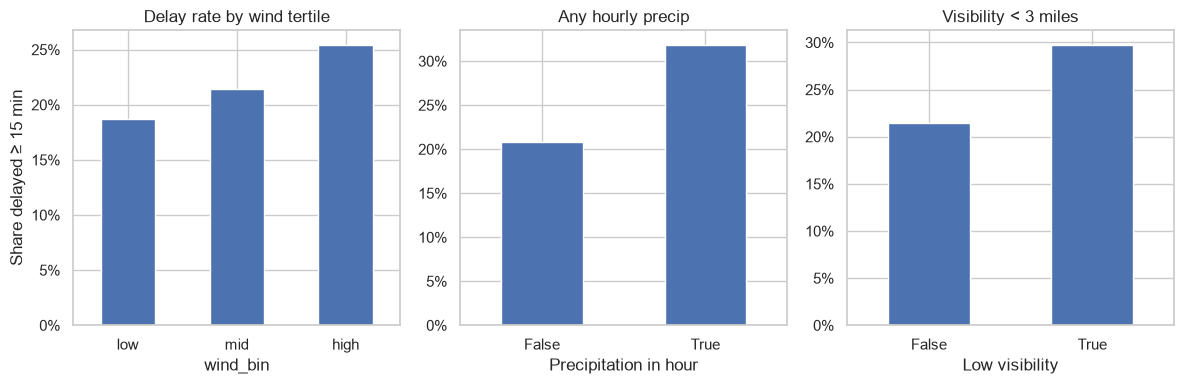

Wind tertiles:
 wind_bin
low     18.7%
mid     21.4%
high    25.5%
Name: DepDel15, dtype: str
Precip:
 had_precip
False    20.8%
True     31.9%
Name: DepDel15, dtype: str
Low visibility:
 low_vsby
False    21.4%
True     29.8%
Name: DepDel15, dtype: str


In [14]:
wx_eda = flights_wx.copy()
wx_eda["wind_bin"] = pd.qcut(wx_eda["sknt"], 3, labels=["low", "mid", "high"])
wx_eda["had_precip"] = wx_eda["p01i"].fillna(0) > 0
wx_eda["low_vsby"] = wx_eda["vsby"] < 3

wind_rates = wx_eda.groupby("wind_bin", observed=True)["DepDel15"].mean()
precip_rates = wx_eda.groupby("had_precip")["DepDel15"].mean()
vsby_rates = wx_eda.groupby("low_vsby")["DepDel15"].mean()

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
wind_rates.plot(kind="bar", ax=axes[0], color="#4C72B0", rot=0)
axes[0].set_title("Delay rate by wind tertile")
axes[0].set_ylabel("Share delayed ≥ 15 min")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))

precip_rates.plot(kind="bar", ax=axes[1], color="#4C72B0", rot=0)
axes[1].set_title("Any hourly precip")
axes[1].set_xlabel("Precipitation in hour")
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))

vsby_rates.plot(kind="bar", ax=axes[2], color="#4C72B0", rot=0)
axes[2].set_title("Visibility < 3 miles")
axes[2].set_xlabel("Low visibility")
axes[2].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))

plt.tight_layout()
plt.show()

print("Wind tertiles:\n", wind_rates.map(lambda x: f"{x:.1%}"))
print("Precip:\n", precip_rates.map(lambda x: f"{x:.1%}"))
print("Low visibility:\n", vsby_rates.map(lambda x: f"{x:.1%}"))

Worse weather lines up with higher delay risk: high-wind hours (~25%) exceed low-wind hours (~19%), hours with precip jump to ~32% vs ~21% without, and low visibility (~30%) exceeds clearer conditions (~21%). Weather belongs in the model, not just as a narrative aside.

## 4. Data splitting (train, validation, test)

Use a chronological split so the model is judged on future flights, not a random shuffle that leaks summer patterns into winter. Working cutoffs for 2023: train Jan-Aug, validation Sep-Oct, test Nov-Dec.


In [15]:
train_end = pd.Timestamp("2023-08-31")
val_end = pd.Timestamp("2023-10-31")

train_mask = flights_wx["FlightDate"] <= train_end
val_mask = (flights_wx["FlightDate"] > train_end) & (flights_wx["FlightDate"] <= val_end)
test_mask = flights_wx["FlightDate"] > val_end

train_df = flights_wx.loc[train_mask].copy()
val_df = flights_wx.loc[val_mask].copy()
test_df = flights_wx.loc[test_mask].copy()


def split_summary(name, frame):
 return {
 "split": name,
 "rows": len(frame),
 "share": len(frame) / len(flights_wx),
 "delay_rate": frame["DepDel15"].mean(),
 "start": frame["FlightDate"].min().date(),
 "end": frame["FlightDate"].max().date(),
 }


split_table = pd.DataFrame(
 [
 split_summary("train", train_df),
 split_summary("validation", val_df),
 split_summary("test", test_df),
 ]
)
print(split_table.to_string(index=False))
assert train_df["FlightDate"].max() < val_df["FlightDate"].min()
assert val_df["FlightDate"].max() < test_df["FlightDate"].min()
print("\nChronological order checks passed.")


     split   rows    share  delay_rate      start        end
     train 593199 0.658387    0.240191 2023-01-01 2023-08-31
validation 156824 0.174058    0.185144 2023-09-01 2023-10-31
      test 150966 0.167556    0.156373 2023-11-01 2023-12-30

Chronological order checks passed.


Train covers the busy summer peak; validation and test are later months with lower baseline delay rates. That is intentional and harder than a random split: the model must generalize forward in time. Hyperparameters will be chosen on validation only; the test set stays untouched until final selection.

## 5. Model building strategy and research questions

Research questions:
1. Can schedule + origin weather features beat a simple baseline on later months?
2. Which signals matter most for flagging delay risk before departure?
3. Given false negatives (missed delays) are costlier than false positives (extra attention), can we choose a threshold that improves recall without drowning operations in alerts?

Approach: majority-class baseline → logistic regression (interpretable) → histogram gradient boosting (non-linear). Tune on validation only; evaluate the chosen model once on the test set. The business framing is a same-day watch list before each busy departure window, not overnight planning that requires perfect evening forecasts.


### 5.1 Shared feature matrix and evaluation helpers


In [16]:
cat_features = ["Origin", "Dest", "Reporting_Airline"]
num_features = ["Month", "DayOfWeek", "crs_dep_hour", "Distance", "tmpf", "dwpf", "sknt", "p01i", "vsby"]
assert set(cat_features + num_features) == set(MODEL_FEATURES_WX)

X_train = train_df[MODEL_FEATURES_WX]
y_train = train_df["DepDel15"].astype(int)
X_val = val_df[MODEL_FEATURES_WX]
y_val = val_df["DepDel15"].astype(int)
X_test = test_df[MODEL_FEATURES_WX]
y_test = test_df["DepDel15"].astype(int)

print(f"Train: {len(X_train):,} | Val: {len(X_val):,} | Test: {len(X_test):,}")
print(f"Train delay rate: {y_train.mean():.3%} | Val: {y_val.mean():.3%} | Test: {y_test.mean():.3%}")


def evaluate_scores(name, y_true, proba, threshold=0.5):
 """Business-relevant metrics for a delay-risk score."""
 y_pred = (proba >= threshold).astype(int)
 precision, recall, f1, _ = precision_recall_fscore_support(
 y_true, y_pred, average="binary", zero_division=0
 )
 return {
 "model": name,
 "threshold": threshold,
 "roc_auc": roc_auc_score(y_true, proba),
 "avg_precision": average_precision_score(y_true, proba),
 "precision": precision,
 "recall": recall,
 "f1": f1,
 "flag_rate": y_pred.mean(),
 }


Train: 593,199 | Val: 156,824 | Test: 150,966
Train delay rate: 24.019% | Val: 18.514% | Test: 15.637%


### 5.2 Baseline: predict using the training-set delay rate

Every flight gets the same score equal to the training positive rate. Predictions at 0.5 therefore match the majority class (always on-time), which is an honest floor for ranking metrics.


In [17]:
train_base_rate = float(y_train.mean())
baseline_val_proba = np.full(len(y_val), train_base_rate)
baseline_metrics = evaluate_scores("baseline_train_rate", y_val, baseline_val_proba)
pd.DataFrame([baseline_metrics])


,model,threshold,roc_auc,avg_precision,precision,recall,f1,flag_rate
0,baseline_train_rate,0.5,0.5,0.185144,0.0,0.0,0.0,0.0


## 6. Model performance and hyperparameter tuning

All tuning uses the validation window only. We compare ROC-AUC and average precision (ranking quality) plus recall/precision at a fixed threshold, then optionally shift the threshold to favor catching more delays.


### 6.1 Logistic regression


In [18]:
preprocess_linear = ColumnTransformer(
 transformers=[
 ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_features),
 ("num", StandardScaler(), num_features),
 ]
)

logit_candidates = []
for C in (0.1, 1.0, 3.0):
 pipe = Pipeline(
 steps=[
 ("prep", preprocess_linear),
 (
 "model",
 LogisticRegression(
 C=C,
 class_weight="balanced",
 max_iter=1000,
 random_state=RANDOM_STATE,
 ),
 ),
 ]
 )
 pipe.fit(X_train, y_train)
 proba = pipe.predict_proba(X_val)[:, 1]
 row = evaluate_scores(f"logit_C={C}", y_val, proba)
 row["estimator"] = pipe
 logit_candidates.append(row)

logit_val = pd.DataFrame([{k: v for k, v in r.items() if k != "estimator"} for r in logit_candidates])
logit_val = logit_val.sort_values("avg_precision", ascending=False)
print(logit_val.to_string(index=False))
best_logit = max(logit_candidates, key=lambda r: r["avg_precision"])
print("Selected logistic:", best_logit["model"])


      model  threshold  roc_auc  avg_precision  precision   recall       f1  flag_rate
logit_C=1.0        0.5 0.655504       0.310612   0.265205 0.616187 0.370813   0.430170
logit_C=0.1        0.5 0.655371       0.310583   0.264811 0.616084 0.370409   0.430738
logit_C=3.0        0.5 0.655326       0.310353   0.264749 0.616394 0.370404   0.431056
Selected logistic: logit_C=1.0


### 6.2 Histogram gradient boosting


In [19]:
preprocess_tree = ColumnTransformer(
 transformers=[
 ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_features),
 ("num", "passthrough", num_features),
 ]
)

hgb_grid = [
 {"max_depth": 6, "learning_rate": 0.05, "max_iter": 200},
 {"max_depth": 8, "learning_rate": 0.05, "max_iter": 300},
 {"max_depth": 8, "learning_rate": 0.1, "max_iter": 200},
]

hgb_candidates = []
for params in hgb_grid:
 pipe = Pipeline(
 steps=[
 ("prep", preprocess_tree),
 (
 "model",
 HistGradientBoostingClassifier(
 random_state=RANDOM_STATE,
 **params,
 ),
 ),
 ]
 )
 pipe.fit(X_train, y_train)
 proba = pipe.predict_proba(X_val)[:, 1]
 label = (
 f"hgb_depth={params['max_depth']}"
 f"_lr={params['learning_rate']}"
 f"_iter={params['max_iter']}"
 )
 row = evaluate_scores(label, y_val, proba)
 row["estimator"] = pipe
 row["params"] = params
 hgb_candidates.append(row)

hgb_val = pd.DataFrame([{k: v for k, v in r.items() if k not in ("estimator", "params")} for r in hgb_candidates])
hgb_val = hgb_val.sort_values("avg_precision", ascending=False)
print(hgb_val.to_string(index=False))
best_hgb = max(hgb_candidates, key=lambda r: r["avg_precision"])
print("Selected HGB:", best_hgb["model"])


                       model  threshold  roc_auc  avg_precision  precision   recall       f1  flag_rate
hgb_depth=8_lr=0.05_iter=300        0.5 0.693683       0.371698   0.598107 0.071810 0.128225   0.022229
hgb_depth=6_lr=0.05_iter=200        0.5 0.692752       0.371576   0.627973 0.053659 0.098870   0.015820
 hgb_depth=8_lr=0.1_iter=200        0.5 0.693660       0.368218   0.578788 0.072361 0.128639   0.023147
Selected HGB: hgb_depth=8_lr=0.05_iter=300


### 6.3 Validation comparison and threshold choice

Because missed delays are costlier than extra flags, we keep the best ranking model and search a lower decision threshold on validation to raise recall, subject to a flag-rate cap so the alert list stays operable (at most 40% of flights flagged).


In [20]:
val_compare = pd.DataFrame(
 [
 {k: v for k, v in baseline_metrics.items()},
 {k: v for k, v in best_logit.items() if k != "estimator"},
 {k: v for k, v in best_hgb.items() if k not in ("estimator", "params")},
 ]
)
print("Validation comparison (threshold=0.5):")
print(val_compare.to_string(index=False))

# Choose model with best validation average precision
if best_hgb["avg_precision"] >= best_logit["avg_precision"]:
 selected_name = best_hgb["model"]
 selected_model = best_hgb["estimator"]
else:
 selected_name = best_logit["model"]
 selected_model = best_logit["estimator"]

val_proba = selected_model.predict_proba(X_val)[:, 1]
threshold_rows = []
for thr in np.round(np.arange(0.20, 0.55, 0.05), 2):
 row = evaluate_scores(selected_name, y_val, val_proba, threshold=float(thr))
 threshold_rows.append(row)

thr_table = pd.DataFrame(threshold_rows)
# Prefer higher recall, but keep flag_rate <= 40% of flights
eligible = thr_table[thr_table["flag_rate"] <= 0.40]
if eligible.empty:
 chosen_thr_row = thr_table.sort_values("recall", ascending=False).iloc[0]
else:
 chosen_thr_row = eligible.sort_values(["recall", "precision"], ascending=False).iloc[0]

CHOSEN_THRESHOLD = float(chosen_thr_row["threshold"])
print("\nThreshold sweep:")
print(thr_table.to_string(index=False))
print(f"\nChosen model: {selected_name} @ threshold={CHOSEN_THRESHOLD:.2f}")
print(chosen_thr_row.to_frame().T.to_string(index=False))


Validation comparison (threshold=0.5):
                       model  threshold  roc_auc  avg_precision  precision   recall       f1  flag_rate
         baseline_train_rate        0.5 0.500000       0.185144   0.000000 0.000000 0.000000   0.000000
                 logit_C=1.0        0.5 0.655504       0.310612   0.265205 0.616187 0.370813   0.430170
hgb_depth=8_lr=0.05_iter=300        0.5 0.693683       0.371698   0.598107 0.071810 0.128225   0.022229



Threshold sweep:
                       model  threshold  roc_auc  avg_precision  precision   recall       f1  flag_rate
hgb_depth=8_lr=0.05_iter=300       0.20 0.693683       0.371698   0.269747 0.691476 0.388096   0.474602
hgb_depth=8_lr=0.05_iter=300       0.25 0.693683       0.371698   0.325456 0.527432 0.402529   0.300043
hgb_depth=8_lr=0.05_iter=300       0.30 0.693683       0.371698   0.378589 0.415085 0.395998   0.202992
hgb_depth=8_lr=0.05_iter=300       0.35 0.693683       0.371698   0.419622 0.337042 0.373825   0.148708
hgb_depth=8_lr=0.05_iter=300       0.40 0.693683       0.371698   0.460271 0.250181 0.324163   0.100635
hgb_depth=8_lr=0.05_iter=300       0.45 0.693683       0.371698   0.511896 0.148200 0.229855   0.053601
hgb_depth=8_lr=0.05_iter=300       0.50 0.693683       0.371698   0.598107 0.071810 0.128225   0.022229

Chosen model: hgb_depth=8_lr=0.05_iter=300 @ threshold=0.25
                       model threshold   roc_auc avg_precision precision    recall       

Threshold 0.20 flags about 47% of validation flights, which exceeds the 40% operations-style cap, so 0.25 (about 30% flagged) is the highest-recall option within the cap. That is why later slides and the brief cite ~30% rather than 40%.

## 7. Results and final model selection

Refit is unnecessary here because candidates were already fit on train only. We now score the held-out test months once.


In [21]:
test_proba = selected_model.predict_proba(X_test)[:, 1]
test_metrics = evaluate_scores(selected_name, y_test, test_proba, threshold=CHOSEN_THRESHOLD)
test_pred = (test_proba >= CHOSEN_THRESHOLD).astype(int)

print("Test metrics:")
print(pd.DataFrame([test_metrics]).to_string(index=False))
print("\nConfusion matrix [ [TN FP], [FN TP] ]:")
print(confusion_matrix(y_test, test_pred))
print("\nClassification report:")
print(classification_report(y_test, test_pred, digits=3))

# Lift vs baseline on test (same threshold rule on constant score is majority-class)
baseline_test_proba = np.full(len(y_test), train_base_rate)
baseline_test = evaluate_scores("baseline_train_rate", y_test, baseline_test_proba, threshold=0.5)
print("\nTest baseline (majority @ 0.5):")
print(pd.DataFrame([baseline_test]).to_string(index=False))
print(
 f"\nRecall lift vs baseline: {test_metrics['recall'] - baseline_test['recall']:+.3f} | "
 f"Avg precision: {test_metrics['avg_precision']:.3f} vs {baseline_test['avg_precision']:.3f}"
)


Test metrics:
                       model  threshold  roc_auc  avg_precision  precision  recall       f1  flag_rate
hgb_depth=8_lr=0.05_iter=300       0.25 0.644833       0.256465     0.2435 0.47685 0.322379   0.306228

Confusion matrix [ [TN FP], [FN TP] ]:
[[92386 34973]
 [12350 11257]]

Classification report:
              precision    recall  f1-score   support

           0      0.882     0.725     0.796    127359
           1      0.243     0.477     0.322     23607

    accuracy                          0.687    150966
   macro avg      0.563     0.601     0.559    150966
weighted avg      0.782     0.687     0.722    150966


Test baseline (majority @ 0.5):
              model  threshold  roc_auc  avg_precision  precision  recall  f1  flag_rate
baseline_train_rate        0.5      0.5       0.156373        0.0     0.0 0.0        0.0

Recall lift vs baseline: +0.477 | Avg precision: 0.256 vs 0.156


On the Nov-Dec test set, the selected model flagged 30.6% of flights and caught 47.7% of delays (precision 24.3%). Flagging 30.6% of flights at random would catch about 30.6% of delays, so the model is roughly 1.5× random selection at the same review volume. Ranking quality dropped from validation to test (ROC-AUC 0.694 → 0.645; average precision 0.372 → 0.256), which is expected when late-year months differ from the summer-heavy training window.

The selected model is chosen by validation average precision, with a recall-oriented threshold under the flag-rate cap. Test performance is reported once against a majority-class / do-nothing baseline so the business claim stays honest: we are ranking delay risk on future months, not fitting the test window.


### 7.1 What drives the predictions

Permutation importance on the validation set (model-agnostic): shuffle one feature at a time and measure the drop in average precision. This answers which pre-departure signals the selected model relies on most.


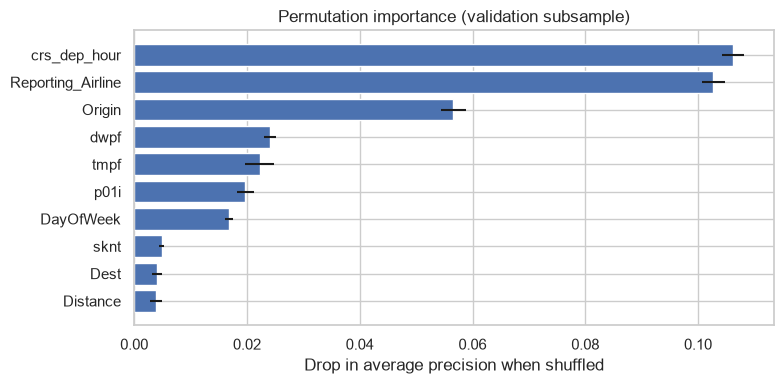

          feature  importance_mean  importance_std
     crs_dep_hour         0.106194        0.001875
Reporting_Airline         0.102735        0.002089
           Origin         0.056618        0.002179
             dwpf         0.024101        0.001132
             tmpf         0.022224        0.002531
             p01i         0.019725        0.001568
        DayOfWeek         0.016818        0.000758
             sknt         0.004878        0.000416
             Dest         0.004056        0.000883
         Distance         0.003913        0.001054


In [22]:
# Permutation importance on a validation subsample for speed / stability
rng = np.random.default_rng(RANDOM_STATE)
n_pi = min(40_000, len(X_val))
pi_idx = rng.choice(len(X_val), size=n_pi, replace=False)
X_pi = X_val.iloc[pi_idx]
y_pi = y_val.iloc[pi_idx]

pi = permutation_importance(
    selected_model,
    X_pi,
    y_pi,
    n_repeats=5,
    random_state=RANDOM_STATE,
    scoring="average_precision",
    n_jobs=-1,
)

pi_table = (
    pd.DataFrame(
        {
            "feature": X_val.columns,
            "importance_mean": pi.importances_mean,
            "importance_std": pi.importances_std,
        }
    )
    .sort_values("importance_mean", ascending=False)
    .reset_index(drop=True)
)

fig, ax = plt.subplots(figsize=(8, 4))
top = pi_table.head(10).iloc[::-1]
ax.barh(top["feature"], top["importance_mean"], xerr=top["importance_std"], color="#4C72B0")
ax.set_xlabel("Drop in average precision when shuffled")
ax.set_title("Permutation importance (validation subsample)")
plt.tight_layout()
plt.show()
print(pi_table.head(10).to_string(index=False))


Larger bars mean the model depends more on that input for ranking delay risk. Scheduled departure hour (importance about 0.106) and reporting airline (about 0.103) matter most, followed by origin airport (about 0.057). Dewpoint, temperature, and precipitation each contribute about 0.02, and day of week about 0.017. Wind, destination, and distance are near zero in this sample.


## 8. Discussion and conclusion

Airport, scheduled hour, and airline, together with origin-hour weather, help separate delayed from on-time departures on later months. The chronological split is stricter than a random split because winter test months have a lower base delay rate than the summer-heavy training window. With training limited to January-August, the `Month` feature cannot teach the model about September-December from calendar month alone, so seasonality enters mainly through weather and related schedule patterns rather than through `Month` as a learned season effect.

Intended use. The score is meant to support a same-day watch list refreshed before each busy departure window. The model uses weather recorded during the scheduled departure hour. A live list refreshed shortly before a busy window would use the most recent reading, typically an hour earlier. Because conditions usually change gradually, this is a close but slightly optimistic stand-in, and longer lead times would require forecasts.

Other limitations: five airports and one year; ASOS weather is airport-local, not runway-specific; no crew, turnaround, or ATC features; carrier effects may proxy network structure; the usable modeling window ends on 2023-12-30 after the weather join, so December 31 is not in the test set. Beyond this course: richer weather-impact products, inbound delay / network features, and live scoring with explicit forecast inputs when longer lead times are required.

GitHub repository: https://github.com/mrosalia96/ads505-flight-delay-prediction


## 9. Model Brief

We framed the problem as a same-day watch list before each busy departure window: flag flights likely to leave 15+ minutes late using schedule fields and origin-hour NOAA ASOS weather. Models compared: constant-rate baseline, class-weighted logistic regression, and histogram gradient boosting. Hyperparameters were chosen on Sep-Oct 2023 validation; Nov-Dec stayed untouched until the end.

The baseline cannot rank flights (majority prediction yields essentially zero delay recall at 0.5). Logistic regression beat it (validation AP 0.311, ROC-AUC 0.656); gradient boosting improved further (AP 0.372, ROC-AUC 0.694). Threshold 0.25 kept about 30% flagged under a 40% cap. On test, the selected model flagged 30.6% of flights and caught 47.7% of delays (precision 24.3%; ROC-AUC 0.645 / AP 0.256). Permutation importance is led by scheduled hour and airline, then origin, then dewpoint, temperature, precipitation, and day of week.

Limits: no gate, turn, or crew data; departure-hour weather is a close but slightly optimistic stand-in for a list refreshed an hour earlier; longer lead times need forecasts; five airports and one year; `Month` is weak for Sep-Dec after Jan-Aug training. Next: pilot on SAN evening departures, add forecast weather if longer lead is required, and monitor calibration on a rolling window.
